# Customer Churn Prediction

In this project, we will examine data from a telecommunications company's customer base. While some customers use the services for many years, others eventually decide to discontinue them.
For the company, losing customers is a problem, as it leads to a decline in revenue. It is therefore valuable to understand what influences these decisions and whether it is possible to identify, in advance, those customers who are planning to leave.
Our goal in this project is to determine which customer segments are most likely to discontinue the services and what characteristics they share. We also aim to find out whether, based on available customer information, it is possible to predict which individuals might leave in the future.

## Opening and Exploring the Data

Let's start by importing the necessary libraries and loading the dataset into a list of lists.

In [3]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

project = Path.home() / "Desktop" / "Customer-Churn-Prediction"
if not (project / "data").exists():
    project = Path.cwd()

csv_path = project / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not csv_path.exists():
    csv_path = Path.cwd() / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(csv_path)
print("Number of rows and columns:", df.shape)
display(df.head())

Number of rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The dataset contains 7,043 rows and 21 columns. 

## Data Quality and Cleaning

Before starting the analysis, I check for missing values and duplicate records.
The `TotalCharges` column is stored as text, so I convert it to a numeric format. I then remove rows with missing values and duplicates.
I also create a new column called `ChurnFlag`, where `1` means the customer left and `0` means they stayed. This will make the analysis and model training easier.

In [4]:
print("Missing values before cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.dropna().drop_duplicates().copy()

df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Number of records after cleaning:", len(df))

display(
    df[["tenure", "MonthlyCharges", "TotalCharges"]]
    .describe()
    .round(2)
)

Missing values before cleaning:
Series([], dtype: int64)
Duplicate rows: 0
Number of records after cleaning: 7032


,tenure,MonthlyCharges,TotalCharges
count,7032.00,7032.00,7032.00
mean,32.42,64.80,2283.30
std,24.55,30.09,2266.77
min,1.00,18.25,18.80
25%,9.00,35.59,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.86,3794.74
max,72.00,118.75,8684.80


After cleaning the data, 7,032 customer records remain. There were no duplicate rows, but 11 records were removed because of missing values in TotalCharges after conversion.

On average, customers have been with the company for about 32 months and pay $64.80 per month.

## How Many Customers Are Leaving?

First, I calculate the churn rate to see what percentage of customers have left the company.
I divide the number of customers who left by the total number of customers and multiply by 100.

,Metric,Value
0,Total Customers,7032.00
1,Churned Customers,1869.00
2,Churn Rate (%),26.58


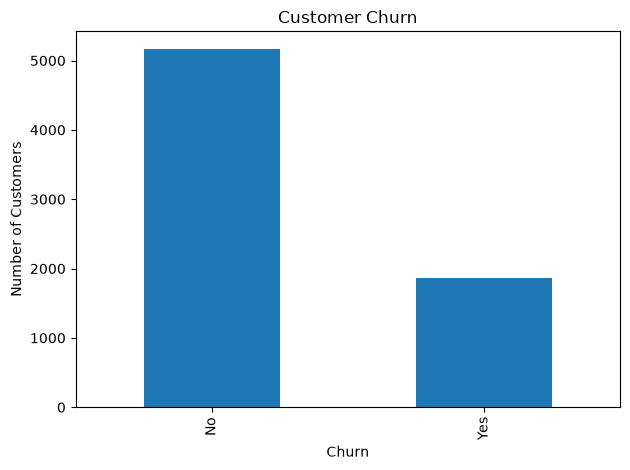

In [6]:
total = len(df)
churned = int(df["ChurnFlag"].sum())
rate = 100 * churned / total

summary = pd.DataFrame({
    "Metric": ["Total Customers", "Churned Customers", "Churn Rate (%)"],
    "Value": [total, churned, round(rate, 2)]
})

display(summary)

df["Churn"].value_counts().plot(
    kind="bar",
    title="Customer Churn"
)

plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Out of 7,032 customers, 1,869 left the company, which gives a churn rate of 26.58%.
Most customers stayed, but more than one in four left. I want to look at different customer groups to understand who is more likely to leave.

## Which Customer Groups Are More Likely to Leave?

I want to check whether some customers are more likely to leave than others.
I will  compare churn rates based on contract type, internet service, technical support, and payment method to see if there are any differences.

In [7]:
groups = ["Contract", "InternetService", "TechSupport", "PaymentMethod"]

for col in groups:
    result = df.groupby(col)["ChurnFlag"].agg(["count", "sum", "mean"])
    result.columns = ["Customers", "Churned", "Churn Rate (%)"]
    result["Churn Rate (%)"] = (result["Churn Rate (%)"] * 100).round(2)

    print(f"Churn by {col}")
    display(result)

Churn by Contract


,Customers,Churned,Churn Rate (%)
Contract,,,
Month-to-month,3875,1655,42.71
One year,1472,166,11.28
Two year,1685,48,2.85


Churn by InternetService


,Customers,Churned,Churn Rate (%)
InternetService,,,
DSL,2416,459,19.00
Fiber optic,3096,1297,41.89
No,1520,113,7.43


Churn by TechSupport


,Customers,Churned,Churn Rate (%)
TechSupport,,,
No,3472,1446,41.65
No internet service,1520,113,7.43
Yes,2040,310,15.20


Churn by PaymentMethod


,Customers,Churned,Churn Rate (%)
PaymentMethod,,,
Bank transfer (automatic),1542,258,16.73
Credit card (automatic),1521,232,15.25
Electronic check,2365,1071,45.29
Mailed check,1604,308,19.20


Customers with month-to-month contracts have the highest churn rate (42.71%), compared to only 2.85% for two-year contracts.
Churn is also higher among customers using fiber optic internet (41.89%) and those without technical support (41.65%).
Customers paying by electronic check have the highest churn rate (45.29%), while those using automatic payments are less likely to leave.
These results show that contract type, internet service, technical support, and payment method are all related to customer churn.

## Visualizing Customer Behavior

I will compare monthly charges and customer tenure to see how they differ between customers who stayed and those who left.

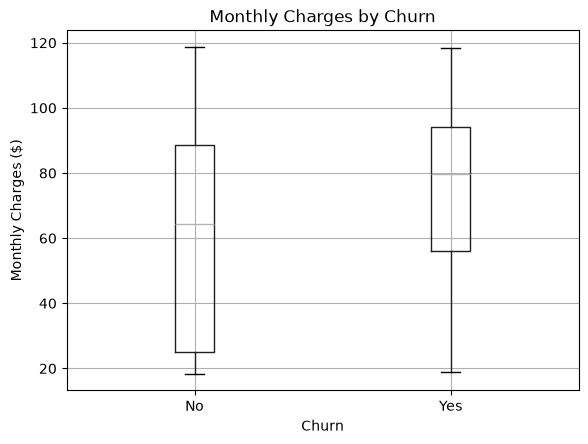

In [9]:
# Monthly charges
df.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges ($)")
plt.show()


Customers who left generally had higher monthly bills. The median is around $80, compared to about $65 for customers who stayed.

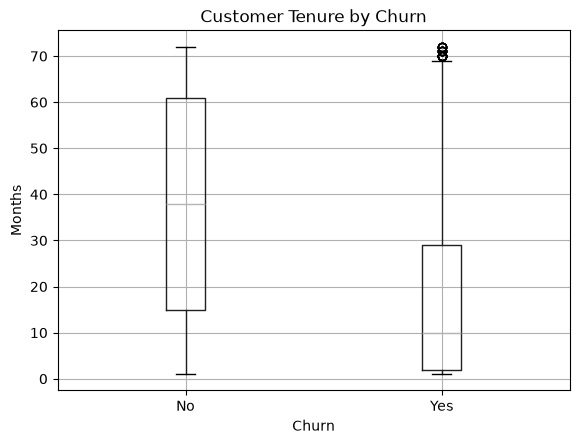

In [10]:
# Customer tenure
df.boxplot(column="tenure", by="Churn")
plt.title("Customer Tenure by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Months")
plt.show()

Customers who left had usually been with the company for a shorter time. Their median tenure is around 10 months, compared to 38 months for customers who stayed.

## Contract Type and Customer Tenure

I want to see how churn differs depending on both contract type and how long customers have been with the company.

Contract,Month-to-month,One year,Two year
TenureGroup,,,
0–12,51.35,10.57,0.00
13–24,37.72,8.12,0.00
25–48,32.92,10.62,2.19
49–72,26.02,12.93,3.33


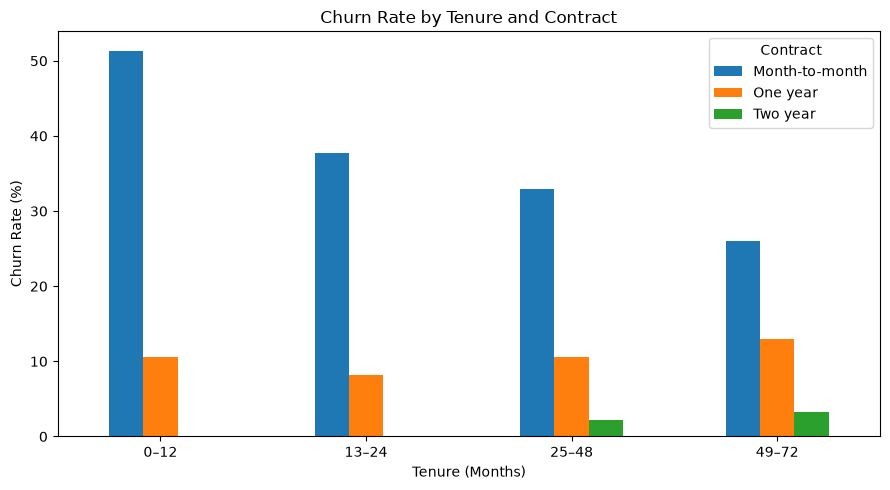

In [14]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"]
)

result = df.pivot_table(
    index="TenureGroup",
    columns="Contract",
    values="ChurnFlag",
    aggfunc="mean",
    observed=True
) * 100

display(result.round(2))

result.plot(kind="bar", figsize=(9, 5))

plt.title("Churn Rate by Tenure and Contract")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Contract")
plt.tight_layout()
plt.show()

Customers with month-to-month contracts are more likely to leave, especially during their first year (51.35%).

The churn rate becomes lower for customers who have been with the company longer. Customers with two-year contracts have the lowest churn rates across the groups.

## Customer Segmentation

I will compare different combinations of contract types, internet services, and payment methods to find which customer groups have the highest churn rates.

In [15]:
segments = (
    df.groupby(["Contract", "InternetService", "PaymentMethod"])["ChurnFlag"]
    .agg(["count", "mean"])
)

segments.columns = ["Customers", "Churn Rate (%)"]
segments["Churn Rate (%)"] = (segments["Churn Rate (%)"] * 100).round(2)

segments = segments[segments["Customers"] >= 30]
segments = segments.sort_values("Churn Rate (%)", ascending=False)

display(segments.head(10))

Customers  \
Contract       InternetService PaymentMethod                          
Month-to-month Fiber optic     Electronic check                1307   
                               Mailed check                     201   
                               Bank transfer (automatic)        327   
                               Credit card (automatic)          293   
               DSL             Electronic check                 474   
                               Mailed check                     367   
                               Credit card (automatic)          185   
One year       Fiber optic     Electronic check                 196   
Month-to-month No              Mailed check                     325   
                               Bank transfer (automatic)         65   

                                                          Churn Rate (%)  
Contract       InternetService PaymentMethod                              
Month-to-month Fiber optic     Electronic check                    60.37  
                               Mailed check                        50.75  
                               Bank transfer (automatic)           45.57  
                               Credit card (automatic)             41.64  
               DSL             Electronic check                    40.51  
                               Mailed check                        30.79  
                               Credit card (automatic)             27.03  
One year       Fiber optic     Electronic check                    26.02  
Month-to-month No              Mailed check                        20.62  
                               Bank transfer (automatic)           20.00

The highest churn rate (60.37%) is among customers with month-to-month contracts, fiber optic internet, and electronic check payments.
This is also a large group, with 1,307 customers, so it could be an important group for the company to focus on.
Customers with month-to-month contracts and fiber optic internet also have high churn rates with other payment methods.

##  Analysis

Next, I will use SQL to compare churn rates across different customer groups.

In [17]:
database_path = project / "data" / "customer_churn.db"

conn = sqlite3.connect(database_path)

df.to_sql("customers", conn, if_exists="replace", index=False)

print("Database created")

Database created


In [18]:
query = """
SELECT
    Contract,
    COUNT(*) AS Customers,
    ROUND(AVG(ChurnFlag) * 100, 2) AS ChurnRate
FROM customers
GROUP BY Contract
ORDER BY ChurnRate DESC
"""

display(pd.read_sql_query(query, conn))

,Contract,Customers,ChurnRate
0,Month-to-month,3875,42.71
1,One year,1472,11.28
2,Two year,1685,2.85


The show that customers with month-to-month contracts have the highest churn rate (42.71%), compared to 2.85% for two-year contracts.

In [19]:
query = """
SELECT
    TechSupport,
    COUNT(*) AS Customers,
    ROUND(AVG(ChurnFlag) * 100, 2) AS ChurnRate
FROM customers
GROUP BY TechSupport
ORDER BY ChurnRate DESC
"""

display(pd.read_sql_query(query, conn))

,TechSupport,Customers,ChurnRate
0,No,3472,41.65
1,Yes,2040,15.20
2,No internet service,1520,7.43


Customers without technical support have a churn rate of 41.65%, compared to 15.20% for customers with technical support. This suggests that technical support may be an important factor in customer retention.

### Monthly Revenue by Contract Type

I will compare monthly revenue across contract types and check how much revenue comes from customers who churned.

In [20]:
query = """
SELECT
    Contract,
    COUNT(*) AS Customers,
    ROUND(SUM(MonthlyCharges), 2) AS MonthlyRevenue,
    ROUND(AVG(MonthlyCharges), 2) AS AvgMonthlyCharge,
    ROUND(SUM(CASE
        WHEN ChurnFlag = 1 THEN MonthlyCharges
        ELSE 0
    END), 2) AS ChurnedMonthlyRevenue
FROM customers
GROUP BY Contract
ORDER BY ChurnedMonthlyRevenue DESC
"""

display(pd.read_sql_query(query, conn))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


,Contract,Customers,MonthlyRevenue,AvgMonthlyCharge,ChurnedMonthlyRevenue
0,Month-to-month,3875,257294.15,66.40,120847.10
1,One year,1472,95796.90,65.08,14118.45
2,Two year,1685,102569.95,60.87,4165.30


Customers with month-to-month contracts account for the largest share of monthly charges $(257,294.15). They also have the highest total monthly charges associated with churned customers (120,847.10).

### Customer Value Analysis

I will compare how long customers stay with the company and how much they spend across different contract types.

In [21]:
query = """
SELECT
    Contract,
    COUNT(*) AS Customers,
    ROUND(AVG(tenure), 2) AS AvgTenure,
    ROUND(AVG(MonthlyCharges), 2) AS AvgMonthlyCharge,
    ROUND(AVG(TotalCharges), 2) AS AvgTotalCharges,
    ROUND(AVG(ChurnFlag) * 100, 2) AS ChurnRate
FROM customers
GROUP BY Contract
ORDER BY AvgTotalCharges DESC
"""

display(pd.read_sql_query(query, conn))

,Contract,Customers,AvgTenure,AvgMonthlyCharge,AvgTotalCharges,ChurnRate
0,Two year,1685,57.07,60.87,3728.93,2.85
1,One year,1472,42.07,65.08,3034.68,11.28
2,Month-to-month,3875,18.04,66.40,1369.25,42.71


Customers with two-year contracts stay with the company for an average of 57 months and have the highest average total charges ($3,728.93).

Customers with month-to-month contracts stay for only 18 months on average and have the highest churn rate (42.71%).

### Identifying High-Risk Customer Groups

I will look at combinations of contract type, internet service, and technical support to identify customer groups with high churn rates.

In [22]:
query = """
SELECT
    Contract,
    InternetService,
    TechSupport,
    COUNT(*) AS Customers,
    SUM(ChurnFlag) AS ChurnedCustomers,
    ROUND(AVG(ChurnFlag) * 100, 2) AS ChurnRate,
    ROUND(AVG(MonthlyCharges), 2) AS AvgMonthlyCharge
FROM customers
GROUP BY Contract, InternetService, TechSupport
HAVING COUNT(*) >= 50
ORDER BY ChurnedCustomers DESC, ChurnRate DESC
LIMIT 10
"""

display(pd.read_sql_query(query, conn))

,Contract,InternetService,TechSupport,Customers,ChurnedCustomers,ChurnRate,AvgMonthlyCharge
0,Month-to-month,Fiber optic,No,1796,1033,57.52,85.49
1,Month-to-month,DSL,No,884,317,35.86,47.50
2,Month-to-month,Fiber optic,Yes,332,129,38.86,95.28
3,Month-to-month,No,No internet service,524,99,18.89,20.41
4,Month-to-month,DSL,Yes,339,77,22.71,57.32
5,One year,Fiber optic,No,313,58,18.53,96.38
6,One year,Fiber optic,Yes,226,46,20.35,102.10
7,One year,DSL,Yes,326,29,8.90,64.33
8,One year,DSL,No,244,24,9.84,57.48
9,Two year,Fiber optic,Yes,308,21,6.82,106.84


The largest group of churned customers consists of people with month-to-month contracts, fiber optic internet, and no technical support.

Out of 1,796 customers in this group, 1,033 left (57.52%).

##  Statistical Analysis

I will use a chi-square test to check whether contract type and customer churn are statistically associated.

H₀: Contract type and churn are independent.

H₁: Contract type and churn are associated.

In [23]:
from scipy.stats import chi2_contingency

# Contract type vs churn
table = pd.crosstab(df["Contract"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

results = pd.DataFrame({
    "Metric": ["Chi-square", "P-value", "Degrees of freedom"],
    "Value": [chi2, p_value, dof]
})

display(table)
display(results)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


,Metric,Value
0,Chi-square,1.179546e+03
1,P-value,7.326182e-257
2,Degrees of freedom,2.000000e+00


The chi-square test shows a statistically significant relationship between contract type and customer churn (χ² = 1179.55, p < 0.001).

Customers with month-to-month contracts have much higher churn rates than those with one-year or two-year contracts.

In [24]:
import numpy as np

n = table.to_numpy().sum()
cramers_v = np.sqrt(
    chi2 / (n * (min(table.shape) - 1))
)

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.410


##  Data Preparation for Churn Prediction

The data is split into training and test sets to build and evaluate the churn prediction model.

### Prepare the features

In [25]:
X = df.drop(columns=["customerID", "Churn", "ChurnFlag"])
y = df["ChurnFlag"]

print("Features:", X.shape)
print("Target:", y.shape)
print("\nChurn distribution:")
display(y.value_counts(normalize=True).mul(100).round(2))

Features: (7032, 20)
Target: (7032,)

Churn distribution:


ChurnFlag
0    73.42
1    26.58
Name: proportion, dtype: float64

I removed `customerID` because it doesn't provide useful information for predicting churn. I also removed `Churn` and `ChurnFlag` from the input features, keeping `ChurnFlag` as the target variable.

The dataset contains 7,032 customers and 20 input features. Around 26.6% of customers left the company, so the classes are not evenly distributed.

### Split the data

I split the data into 80% for training and 20% for testing. This allows me to evaluate the model on customers it hasn't seen during training.

I used `stratify=y` to keep the same proportion of churned and non-churned customers in both datasets.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (5625, 20)
Test set: (1407, 20)


### Train Logistic Regression

I started with Logistic Regression because I'm predicting one of two outcomes: whether a customer stays or leaves.

Before training, I standardized the numerical features and converted categorical variables into numerical values using One-Hot Encoding.

I used a pipeline to keep preprocessing and model training together. This also ensures that the preprocessing steps are fitted only on the training data.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


### Evaluate the model

In [32]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

display(metrics.round(3))

,Metric,Score
0,Accuracy,0.794
1,Precision,0.635
2,Recall,0.527
3,F1-score,0.576
4,ROC-AUC,0.835


The Logistic Regression model achieved 79.4% accuracy and a ROC-AUC score of 0.835.

Precision was 63.5%, meaning that around 63% of customers predicted to leave actually left. Recall was 52.7%, so the model identified just over half of the customers who churned.

Although the overall accuracy looks good, the recall score shows that the model still misses many customers who are likely to leave.

For this project, recall is particularly important because the goal is to identify customers at risk of leaving before the company loses them.

## Compare Classification Models

I will compare Logistic Regression with Random Forest to see which model performs better at predicting customer churn. I'm particularly interested in recall, since missing customers who are likely to leave could be costly for the company.

### Train Random Forest
I will train a Random Forest model to see if it can identify more customers who are likely to leave. Unlike Logistic Regression, Random Forest can capture more complex relationships between customer features.

In [40]:

from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


### Compare Model Performance
Now I will compare both models on the same test data. I'll look at accuracy, precision, recall, F1-score and ROC-AUC to see how they perform.

I'm especially interested in whether Random Forest can identify more customers who actually leave.

In [37]:

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison = pd.DataFrame(results).set_index("Model")

display(comparison.round(3))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.794,0.635,0.527,0.576,0.835
Random Forest,0.792,0.639,0.505,0.564,0.835


### Visualize Model Comparison

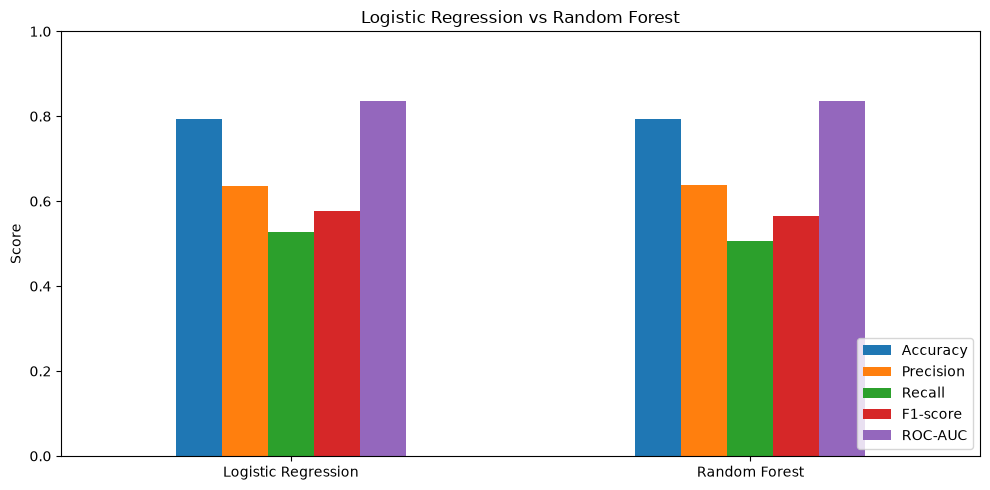

In [38]:

comparison.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Confusion Matrix
I will use confusion matrices to check how many customers each model classified correctly and how many it missed.

I want to focus on false negatives, which are customers who actually left but were predicted to stay.

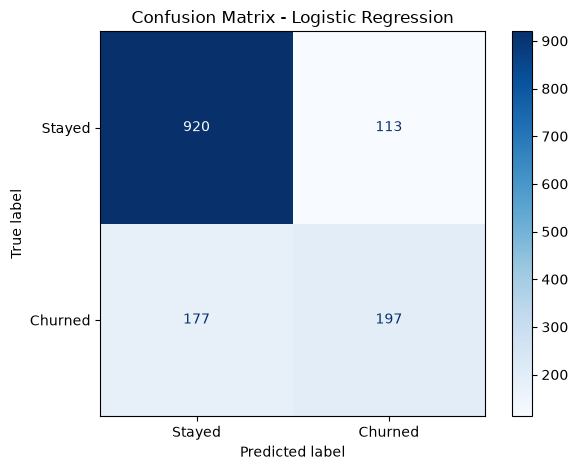

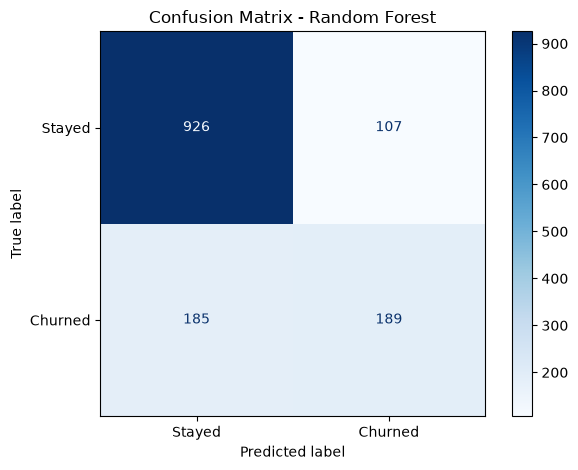

In [39]:

for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Stayed", "Churned"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


Both models achieved similar results, but Logistic Regression performed slightly better overall.

Logistic Regression reached 79.4% accuracy and 52.7% recall, compared to 79.2% accuracy and 50.5% recall for Random Forest. Both models achieved a ROC-AUC score of 0.835.

Looking at the confusion matrices, Logistic Regression correctly identified 197 out of 374 customers who left, while Random Forest identified 189.

Neither model detected all customers at risk. Logistic Regression missed 177 customers, compared to 185 missed by Random Forest.

Based on these results, I will continue with Logistic Regression. It has slightly better recall and F1-score, and its predictions are easier to interpret.

## Improving Recall 

Logistic Regression identified only 52.7% of customers who left. I will test different probability thresholds to see if I can improve recall.

A lower threshold may help identify more customers at risk, although it can also increase the number of false alarms.

In [44]:
import numpy as np

threshold_results = []

for threshold in np.arange(0.2, 0.71, 0.05):
    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,Threshold,Precision,Recall,F1-score
0,0.20,0.456,0.853,0.595
1,0.25,0.490,0.818,0.613
2,0.30,0.511,0.775,0.616
3,0.35,0.563,0.733,0.636
4,0.40,0.587,0.642,0.613
5,0.45,0.601,0.559,0.579
6,0.50,0.639,0.505,0.564
7,0.55,0.668,0.425,0.520
8,0.60,0.711,0.342,0.462
9,0.65,0.740,0.289,0.415


In [47]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]



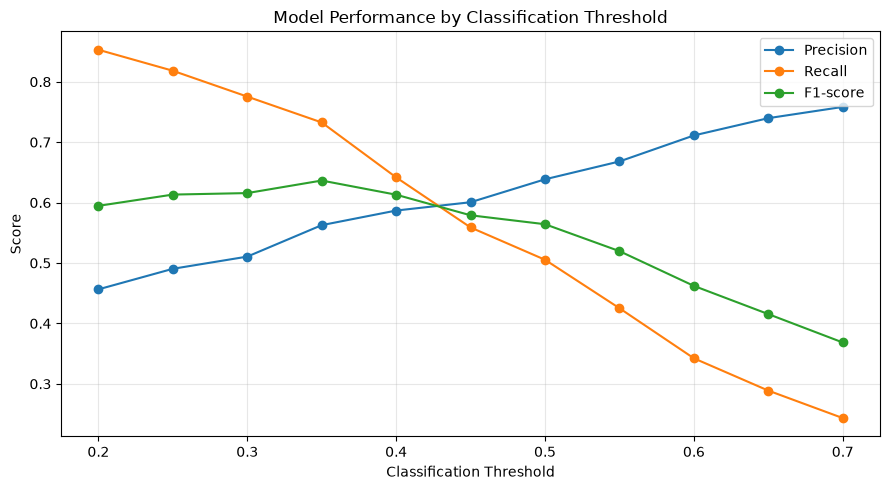

In [48]:
threshold_df.plot(
    x="Threshold",
    y=["Precision", "Recall", "F1-score"],
    marker="o",
    figsize=(9, 5)
)

plt.title("Model Performance by Classification Threshold")
plt.ylabel("Score")
plt.xlabel("Classification Threshold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()




Lowering the classification threshold improved recall, but reduced precision.

The highest F1-score was achieved at a threshold of 0.35 (0.636), with recall of 0.733 and precision of 0.563.

This threshold looks promising because identifying customers at risk is more important than maximizing accuracy alone. However, it also means more customers may be incorrectly flagged as likely to leave.

### Feature Importance Analysis
I want to understand which customer characteristics have the greatest influence on the model's predictions. This can help identify patterns associated with customer churn and support customer retention strategies.

### Feature Importance - Random Forest

In [51]:

import pandas as pd
import matplotlib.pyplot as plt

# Select Random Forest
rf_model = models["Random Forest"]

# Get feature names
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance
importances = rf_model.named_steps[
    "model"
].feature_importances_

# Create a table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(15).round(4))


,Feature,Importance
0,num__tenure,0.1258
1,num__TotalCharges,0.1058
2,cat__Contract_Month-to-month,0.1018
3,num__MonthlyCharges,0.0899
4,cat__OnlineSecurity_No,0.0555
5,cat__InternetService_Fiber optic,0.0497
6,cat__TenureGroup_0–12,0.0478
7,cat__PaymentMethod_Electronic check,0.0417
8,cat__TechSupport_No,0.0396
9,cat__Contract_Two year,0.0235


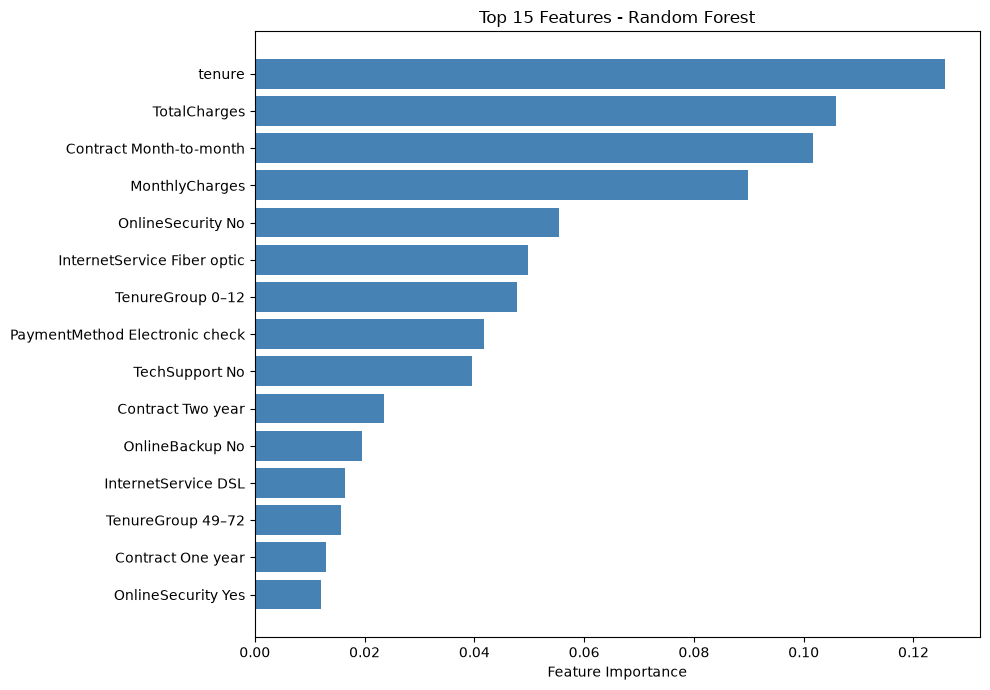

In [52]:

top_features = feature_importance.head(15).copy()

top_features["Feature"] = (
    top_features["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

top_features = top_features.sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="steelblue"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [53]:

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores["test_score"].mean(),
        "Std ROC-AUC": scores["test_score"].std(),
        "Min ROC-AUC": scores["test_score"].min(),
        "Max ROC-AUC": scores["test_score"].max()
    })

cv_table = pd.DataFrame(cv_results)

display(cv_table.round(3))


,Model,Mean ROC-AUC,Std ROC-AUC,Min ROC-AUC,Max ROC-AUC
0,Logistic Regression,0.847,0.007,0.838,0.859
1,Random Forest,0.847,0.006,0.841,0.856


In [54]:

from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=models["Random Forest"],
    param_distributions=param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

best_params = pd.DataFrame(
    random_search.best_params_.items(),
    columns=["Parameter", "Value"]
)

display(best_params)


,Parameter,Value
0,model__n_estimators,200
1,model__min_samples_split,2
2,model__min_samples_leaf,4
3,model__max_features,sqrt
4,model__max_depth,10


In [55]:

tuning_results = pd.DataFrame({
    "Model": [
        "Random Forest - Original",
        "Random Forest - Tuned"
    ],
    "Mean ROC-AUC": [
        cv_table.loc[
            cv_table["Model"] == "Random Forest",
            "Mean ROC-AUC"
        ].iloc[0],
        random_search.best_score_
    ]
})

display(tuning_results.round(4))


,Model,Mean ROC-AUC
0,Random Forest - Original,0.8471
1,Random Forest - Tuned,0.8479


In [56]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

best_rf = random_search.best_estimator_

final_models = {
    "Logistic Regression": logistic_model,
    "Random Forest - Tuned": best_rf
}

final_results = []

for name, model in final_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

final_comparison = pd.DataFrame(final_results)
display(final_comparison.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.794,0.635,0.527,0.576,0.835
1,Random Forest - Tuned,0.790,0.632,0.500,0.558,0.834


### Business Recommendations

The analysis identified several customer groups with higher churn rates.

Customers with month-to-month contracts had the highest churn rate (42.71%), compared to only 2.85% for customers with two-year contracts.

Customers without technical support also showed higher churn rates. The highest-risk segment included customers with month-to-month contracts, fiber optic internet, and no technical support.

Based on these findings, the company could test longer-term contract incentives, improve technical support, and offer targeted retention campaigns to high-risk customers.

The Logistic Regression model could also help identify customers who may need additional attention before they leave.

## Customer Risk Scoring

### Predict Customer Churn Probability

In [58]:

risk_df = X_test.copy()

risk_df["ActualChurn"] = y_test
risk_df["ChurnProbability"] = logistic_model.predict_proba(X_test)[:, 1]

risk_df["RiskLevel"] = pd.cut(
    risk_df["ChurnProbability"],
    bins=[0, 0.3, 0.6, 1],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

risk_df = risk_df.sort_values(
    "ChurnProbability",
    ascending=False
)

display(
    risk_df[
        ["Contract", "tenure", "MonthlyCharges",
         "ChurnProbability", "RiskLevel", "ActualChurn"]
    ].head(15).round(3)
)


,Contract,tenure,MonthlyCharges,ChurnProbability,RiskLevel,ActualChurn
3380,Month-to-month,1,95.10,0.881,High,1
3159,Month-to-month,3,94.85,0.875,High,0
2631,Month-to-month,7,99.25,0.863,High,1
2797,Month-to-month,3,100.95,0.855,High,1
4585,Month-to-month,1,85.05,0.853,High,1
582,Month-to-month,4,89.20,0.851,High,1
3727,Month-to-month,3,96.60,0.850,High,1
933,Month-to-month,4,84.60,0.839,High,1
6240,Month-to-month,1,93.30,0.834,High,1
6574,Month-to-month,9,90.10,0.823,High,0


### Customer Risk Distribution
We will check how many customers belong to each risk category.

In [59]:

risk_summary = (
    risk_df.groupby("RiskLevel", observed=True)
    .agg(
        Customers=("ChurnProbability", "size"),
        AvgChurnProbability=("ChurnProbability", "mean"),
        ActualChurnRate=("ActualChurn", "mean")
    )
    .reset_index()
)

risk_summary["AvgChurnProbability"] *= 100
risk_summary["ActualChurnRate"] *= 100

display(risk_summary.round(2))


,RiskLevel,Customers,AvgChurnProbability,ActualChurnRate
0,Low,846,9.40,10.52
1,Medium,352,44.34,40.62
2,High,209,71.03,67.94


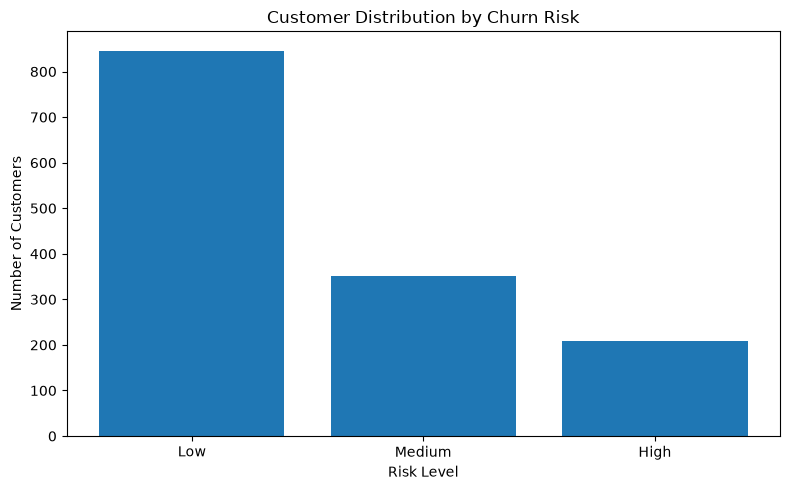

In [60]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    risk_summary["RiskLevel"].astype(str),
    risk_summary["Customers"]
)

plt.title("Customer Distribution by Churn Risk")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()




The model divided 1,407 customers into three risk groups.

Most customers (846) were classified as low risk, with an actual churn rate of 10.52%. The medium-risk group included 352 customers, with a churn rate of 40.62%.

The high-risk group contained 209 customers, and 67.94% of them actually churned.

These results show that the model can distinguish between customers with different levels of churn risk. The high-risk group could be a useful starting point for targeted retention campaigns.

## Final Conclusions

The analysis showed that customer churn is strongly associated with contract type, customer tenure, and the services customers use.
Customers with month-to-month contracts had a churn rate of 42.71%, compared to just 2.85% for customers with two-year contracts. Customers without technical support also had higher churn rates.
I trained and compared Logistic Regression and Random Forest models. Logistic Regression achieved slightly better results, with an accuracy of 79.4%, an F1-score of 0.576, and a ROC-AUC of 0.835.
I also tested different classification thresholds, used cross-validation, and tuned the Random Forest model. Hyperparameter tuning resulted in only a small improvement in cross-validation performance.
Finally, I used Logistic Regression to group customers by their predicted churn risk. The high-risk group had an actual churn rate of 67.94%, compared to 10.52% in the low-risk group.
These findings could help a telecom company identify customers at risk of leaving and prioritize retention efforts. Before real-world deployment, the model would need further validation, and the impact of retention campaigns would need to be tested.